# 4. Residual Networks, Skip Connections and U-Net

Practice for module 4: higher-order logic from stacked layers, vanishing gradients in a deep plain
network vs a residual one, addition vs concatenation, transpose convolution as a matrix, and a tiny
U-Net forward pass with shape tracing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 4.1 Higher-order logic: AND of earlier neurons

Layer 1 neurons detect half-planes; a layer-2 neuron that ANDs them detects a square,
a concept no single layer-1 neuron can express.

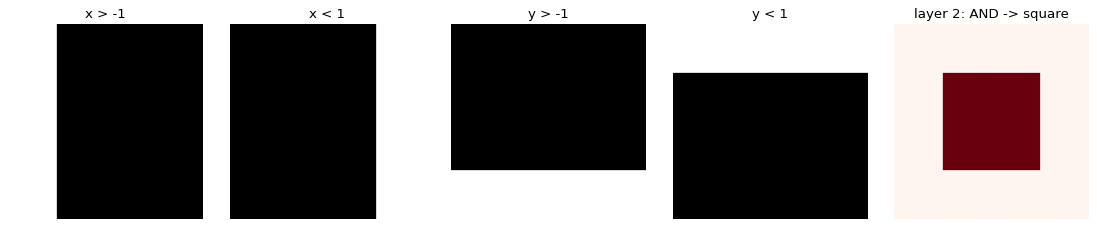

In [2]:
step = lambda z: (z > 0).astype(float)
gx, gy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
P = np.c_[gx.ravel(), gy.ravel()]

W1 = np.array([[1, 0], [-1, 0], [0, 1], [0, -1]], float).T   # x>-1, x<1, y>-1, y<1
b1 = np.ones(4)
h = step(P @ W1 + b1)                    # first-order features
square = step(h.sum(1) - 3.5)            # AND = all four active

fig, axes = plt.subplots(1, 5, figsize=(14, 2.8))
for i, t in enumerate(["x > -1", "x < 1", "y > -1", "y < 1"]):
    axes[i].imshow(h[:, i].reshape(gx.shape), origin="lower", cmap="Greys"); axes[i].set_title(t)
axes[4].imshow(square.reshape(gx.shape), origin="lower", cmap="Reds"); axes[4].set_title("layer 2: AND -> square")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 4.2 Vanishing gradients: plain vs residual

A stack of `L` layers `h = tanh(W h)` vs `h = h + tanh(W h)`. We backprop a unit gradient from the
top and record its norm at every layer. In the plain net the gradient is a product of Jacobians;
the residual Jacobian is `I + ...`, so an additive path keeps the gradient alive.

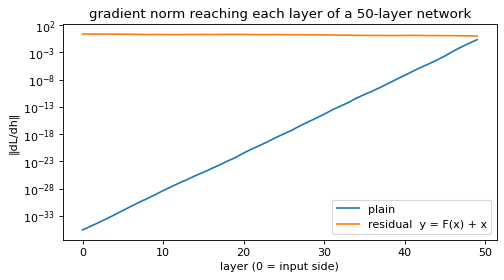

gradient at layer 0: plain 2.75e-36, residual 2.28e+00


In [3]:
def grad_norms(L=50, d=32, residual=False, scale=0.2):
    Ws = [rng.normal(0, scale / np.sqrt(d), (d, d)) for _ in range(L)]
    h, pre = rng.normal(size=d), []
    for W in Ws:
        z = W @ h; pre.append(z)
        h = h + np.tanh(z) if residual else np.tanh(z)
    g, norms = np.ones(d) / np.sqrt(d), []
    for W, z in zip(reversed(Ws), reversed(pre)):
        local = W.T @ (g * (1 - np.tanh(z) ** 2))
        g = g + local if residual else local
        norms.append(np.linalg.norm(g))
    return norms[::-1]

plain, res = grad_norms(), grad_norms(residual=True)
plt.figure(figsize=(7, 3.5))
plt.semilogy(plain, label="plain"); plt.semilogy(res, label="residual  y = F(x) + x")
plt.xlabel("layer (0 = input side)"); plt.ylabel("‖dL/dh‖"); plt.legend()
plt.title("gradient norm reaching each layer of a 50-layer network"); plt.show()
print(f"gradient at layer 0: plain {plain[0]:.2e}, residual {res[0]:.2e}")

## 4.3 A residual block learns only the difference

If the desired mapping is close to identity, `F` only has to learn a small correction. With `F = 0`
the block already passes the input through unchanged. Note the addition happens before the activation.

In [4]:
def residual_block(x, W1, W2):
    F = W2 @ np.maximum(0, W1 @ x)          # residual branch
    return np.maximum(0, F + x)             # add, then activate

x = np.abs(rng.normal(size=6))
zeros = np.zeros((6, 6))
print("x                 :", x)
print("block with F = 0  :", residual_block(x, zeros, zeros), "(identity)")
W1s, W2s = rng.normal(0, 0.1, (6, 6)), rng.normal(0, 0.1, (6, 6))
print("block, small F    :", residual_block(x, W1s, W2s))

x                 : [0.752 1.185 0.293 1.184 0.809 0.698]
block with F = 0  : [0.752 1.185 0.293 1.184 0.809 0.698] (identity)
block, small F    : [0.779 1.146 0.361 1.122 0.772 0.772]


## 4.4 Addition vs concatenation of feature maps

In [5]:
a = rng.normal(size=(16, 32, 32))           # (channels, H, W)
b = rng.normal(size=(16, 32, 32))
c = rng.normal(size=(8, 32, 32))

print("add  (16,32,32)+(16,32,32) ->", (a + b).shape, "  channels preserved")
print("cat  (16,32,32)|(8,32,32)  ->", np.concatenate([a, c], axis=0).shape, "  channels grow")
try:
    a + c
except ValueError as e:
    print("add with different channel counts fails:", e)

add  (16,32,32)+(16,32,32) -> (16, 32, 32)   channels preserved
cat  (16,32,32)|(8,32,32)  -> (24, 32, 32)   channels grow
add with different channel counts fails: operands could not be broadcast together with shapes (16,32,32) (8,32,32) 


## 4.5 Transpose convolution = multiplying by the transposed convolution matrix

A stride-2 1D convolution can be written as a matrix `C` (shrinks 8 -> 3). `C^T` maps 3 -> 8:
that is a transpose convolution, a learnable upsampling whose output depends on input and kernel.

In [6]:
def conv_matrix(n, k, s):
    out = (n - len(k)) // s + 1
    C = np.zeros((out, n))
    for i in range(out):
        C[i, i * s:i * s + len(k)] = k
    return C

k = np.array([1.0, 2.0, 1.0])
C = conv_matrix(8, k, s=2)
x = np.arange(8, dtype=float)
print("C shape:", C.shape, " conv(x) =", C @ x)

y = np.array([1.0, 0.0, 2.0])
up = C.T @ y
print("C^T shape:", C.T.shape, " transpose conv(y) =", up)

# The same thing written as "stamp the kernel at stride-spaced positions and sum overlaps"
stamp = np.zeros(8)
for i, v in enumerate(y):
    stamp[i * 2:i * 2 + 3] += v * k
print("stamping == C^T y:", np.allclose(stamp, up))

C shape: (3, 8)  conv(x) = [ 4. 12. 20.]
C^T shape: (8, 3)  transpose conv(y) = [1. 2. 1. 0. 2. 4. 2. 0.]
stamping == C^T y: True


## 4.6 2D transpose convolution and a tiny U-Net

Encoder: conv -> ReLU -> 2×2 maxpool (twice). Bottleneck: conv. Decoder: 2×2 stride-2 transpose conv,
concatenate the skip connection from the matching encoder level, conv. A 1×1 conv + sigmoid outputs a
mask the same size as the input. Weights are random: the point is the data flow and the shapes.

input                (1, 32, 32)
enc1 conv            (8, 32, 32)
pool1                (8, 16, 16)
enc2 conv            (16, 16, 16)
pool2                (16, 8, 8)
bottleneck           (32, 8, 8)
up2 (tconv)          (16, 16, 16)
cat skip enc2        (32, 16, 16)
dec2 conv            (16, 16, 16)
up1 (tconv)          (8, 32, 32)
cat skip enc1        (16, 32, 32)
dec1 conv            (8, 32, 32)
1x1 conv + sigmoid   (1, 32, 32)


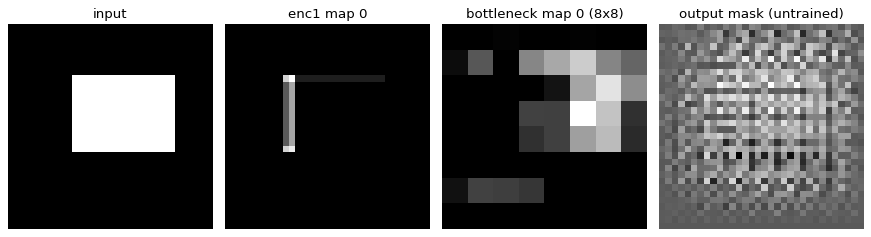

In [7]:
def conv2d(x, w, b, p=1):
    """x: (C,H,W), w: (F,C,k,k), stride 1."""
    F, C, k, _ = w.shape
    xp = np.pad(x, ((0, 0), (p, p), (p, p)))
    H, W = x.shape[1] + 2 * p - k + 1, x.shape[2] + 2 * p - k + 1
    win = np.lib.stride_tricks.sliding_window_view(xp, (k, k), axis=(1, 2))[:, :H, :W]  # (C,H,W,k,k)
    return np.einsum("chwij,fcij->fhw", win, w) + b[:, None, None]

def tconv2x2(x, w, b):
    """Transpose conv, kernel 2, stride 2: each input pixel stamps a 2x2 block. w: (C_in, F, 2, 2)."""
    out = np.einsum("chw,cfij->fhiwj", x, w)
    F, H, _, W, _ = out.shape
    return out.reshape(F, 2 * H, 2 * W) + b[:, None, None]

def maxpool(x): C, H, W = x.shape; return x.reshape(C, H // 2, 2, W // 2, 2).max(axis=(2, 4))
relu = lambda x: np.maximum(0, x)
def cw(f, c, k=3): return rng.normal(0, np.sqrt(2 / (c * k * k)), (f, c, k, k)), np.zeros(f)

log = []
def track(name, t): log.append((name, t.shape)); return t

img = np.zeros((1, 32, 32)); img[0, 8:20, 10:26] = 1.0
x0 = track("input", img)
e1 = track("enc1 conv", relu(conv2d(x0, *cw(8, 1))))
p1 = track("pool1", maxpool(e1))
e2 = track("enc2 conv", relu(conv2d(p1, *cw(16, 8))))
p2 = track("pool2", maxpool(e2))
bn = track("bottleneck", relu(conv2d(p2, *cw(32, 16))))
u2 = track("up2 (tconv)", tconv2x2(bn, rng.normal(0, 0.2, (32, 16, 2, 2)), np.zeros(16)))
c2 = track("cat skip enc2", np.concatenate([u2, e2]))
d2 = track("dec2 conv", relu(conv2d(c2, *cw(16, 32))))
u1 = track("up1 (tconv)", tconv2x2(d2, rng.normal(0, 0.2, (16, 8, 2, 2)), np.zeros(8)))
c1 = track("cat skip enc1", np.concatenate([u1, e1]))
d1 = track("dec1 conv", relu(conv2d(c1, *cw(8, 16))))
mask = track("1x1 conv + sigmoid", 1 / (1 + np.exp(-conv2d(d1, *cw(1, 8, k=1), p=0))))

for name, shape in log:
    print(f"{name:20s} {shape}")

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for a, (t, ttl) in zip(axes, [(img[0], "input"), (e1[0], "enc1 map 0"), (bn[0], "bottleneck map 0 (8x8)"), (mask[0], "output mask (untrained)")]):
    a.imshow(t, cmap="gray"); a.set_title(ttl); a.axis("off")
plt.tight_layout(); plt.show()